In [158]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import glob

plot_folder = "plots/investigate_p_values"
os.makedirs(plot_folder, exist_ok=True)

# set global fontsize to 8
plt.rcParams.update({'font.size': 8})

In [178]:
csv_files = glob.glob(f"../data/DEG_pbs_vs_pbs/results_*.csv")
# Load all CSV files and store them in a list
all_data = []
for file in csv_files:
    # Extract cell type from filename
    cell_type = os.path.basename(file).replace("results_", "").replace(".csv", "")
    # Read the CSV file
    df = pd.read_csv(file, index_col=0)
    # Add cell type as a column
    df["cell_type"] = cell_type
    # Append to the list
    all_data.append(df)

# Concatenate all dataframes
combined_data = pd.concat(all_data, ignore_index=True)
combined_data["comparison"] = combined_data["contrast"] + " vs " + combined_data["baseline"]
comparisons_to_keep = combined_data["comparison"].apply(lambda x: int(x.split(" vs ")[0][1:]) < int(x.split(" vs ")[1][1:]))
combined_data = combined_data[comparisons_to_keep]

In [210]:
target_comparisons = ["H7 vs H11", "H7 vs H12", "H8 vs H11", "H8 vs H12"]
combined_data = combined_data[combined_data["comparison"].isin(target_comparisons)]
combined_data_significant = combined_data[combined_data["significant_0_05"]]
value_counts = combined_data_significant["variable"].value_counts()
vulnerable_genes = value_counts[value_counts > 20].index

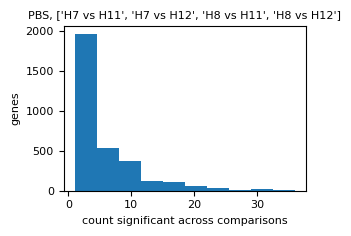

In [211]:
plt.figure(figsize=(3.2,2.4))
plt.hist(value_counts)
plt.xlabel("count significant across comparisons")
plt.ylabel("genes")
plt.title(f"PBS, {target_comparisons}", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "PBS_count_significant"), dpi=300)

In [212]:
value_counts.head(10)

variable
PLEC        36
MYH9        36
7SK         36
SART1       36
NUMA1       36
CDK5RAP3    35
DHX38       35
ZNF581      34
H1-4        34
CD2BP2      33
Name: count, dtype: int64

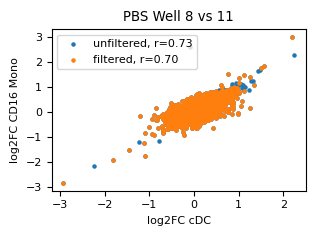

In [213]:
combined_data_filter = combined_data[combined_data["comparison"] == "H8 vs H11"]
combined_data_cDC = combined_data_filter[combined_data_filter["cell_type"] == "cDC"]
combined_data_mono = combined_data_filter[combined_data_filter["cell_type"] == "CD16 Mono"]

combined_data_cDC = combined_data_cDC.set_index("variable")["log_fc"]
combined_data_mono = combined_data_mono.set_index("variable")["log_fc"]

common_index = combined_data_cDC.index.intersection(combined_data_mono.index)
common_index_filter = common_index[~common_index.isin(vulnerable_genes)]
combined_data_mono = combined_data_mono.loc[common_index]
combined_data_cDC = combined_data_cDC.loc[common_index]

plt.figure(figsize=(3.2,2.4))
r= np.corrcoef(combined_data_cDC, combined_data_mono)[0,1]
plt.scatter(combined_data_cDC, combined_data_mono, s=5, label=f"unfiltered, r={r:.2f}")
r_filtered = np.corrcoef(combined_data_cDC.loc[common_index_filter], combined_data_mono.loc[common_index_filter])[0,1]
plt.scatter(combined_data_cDC.loc[common_index_filter], combined_data_mono.loc[common_index_filter], s=5, label=f"filtered, r={r_filtered:.2f}")
plt.xlabel("log2FC cDC")
plt.ylabel("log2FC CD16 Mono")
plt.title("PBS Well 8 vs 11")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "PBS_cDC_CD16_mono_correlation"), dpi=300)

In [214]:
real_values = pd.read_csv(os.path.join(f"./output_tables/", "2_edger_df_log2FoldChange.csv"), header=[0, 1], index_col=0)
real_values = real_values.unstack()
real_values = real_values.reset_index()
real_values.columns = ["cell_type", "comparison", "variable", "log_fc"]
real_values = real_values[real_values["comparison"].isin(["4-1BBL"])]

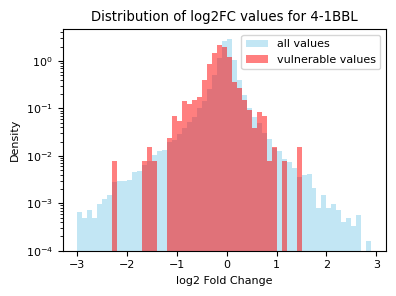

In [215]:
real_values_subset = real_values[real_values["variable"].isin(vulnerable_genes)]
plt.figure(figsize=(4, 3))
plt.hist(real_values["log_fc"], label="all values", color='skyblue', density=True, bins=np.arange(-3, 3, 0.1), alpha=0.5)
plt.hist(real_values_subset["log_fc"], label="vulnerable values", color='red', density=True, bins=np.arange(-3, 3, 0.1), alpha=0.5)
plt.legend()
plt.xlabel("log2 Fold Change")
plt.ylabel("Density")
plt.title("Distribution of log2FC values for 4-1BBL")
plt.yscale("log")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "vulnerable_genes_distribution.png"), dpi=300)
plt.show()

In [218]:
real_values = pd.read_csv(os.path.join(f"./output_tables/", "2_edger_df_log2FoldChange.csv"), header=[0, 1], index_col=0)

In [219]:
cell_type_1 = "cDC"
cell_type_2 = "CD16 Mono"
vals_1 = real_values[(cell_type_1, "4-1BBL")].dropna()
vals_2 = real_values[(cell_type_2, "4-1BBL")].dropna()
common_index = vals_1.index.intersection(vals_2.index)
vals_1 = vals_1.loc[common_index]
vals_2 = vals_2.loc[common_index]
common_index_filter = common_index[~common_index.isin(vulnerable_genes)]
vals_1_filter = vals_1.loc[common_index_filter]
vals_2_filter = vals_2.loc[common_index_filter]

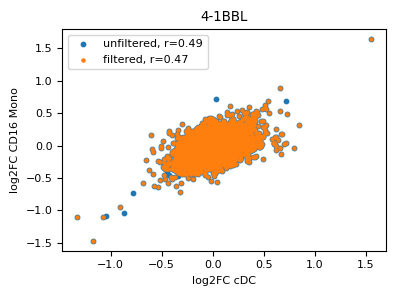

In [220]:
plt.figure(figsize=(4,3))
r = np.corrcoef(vals_1, vals_2)[0,1]
r_filtered = np.corrcoef(vals_1_filter, vals_2_filter)[0,1]
plt.scatter(vals_1, vals_2, s=10, label=f"unfiltered, r={r:.2f}", zorder=1)
plt.scatter(vals_1_filter, vals_2_filter, s=5, label=f"filtered, r={r_filtered:.2f}", zorder=2)
plt.xlabel("log2FC cDC")
plt.ylabel("log2FC CD16 Mono")
plt.title("4-1BBL")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "41bbl_cDC_CD16_mono_correlation_filtered"), dpi=300)


# Other stuff

In [69]:
# # Create a figure with subplots for each comparison
# comparisons = data["comparison"].unique()
# n_comparisons = len(comparisons)
# fig, axes = plt.subplots(n_comparisons, 1, figsize=(6, n_comparisons * 2), sharex=True)

# # Plot histogram for each comparison
# for i, comparison in enumerate(comparisons):
#     subset_df = data[data["comparison"] == comparison]
#     axes[i].hist(np.log10(subset_df["p_value"]), bins=30, color='skyblue', edgecolor='black')
#     axes[i].set_ylabel('Frequency')
#     axes[i].set_yscale('log')
#     axes[i].set_title(f'Distribution of p-values: {comparison}')
#     axes[i].grid(True, alpha=0.3)

# # Set common x-label
# plt.xlabel('Log10(p-value)')
# plt.tight_layout()
# plt.savefig(os.path.join(plot_folder, "p_value_dist"), dpi=300)

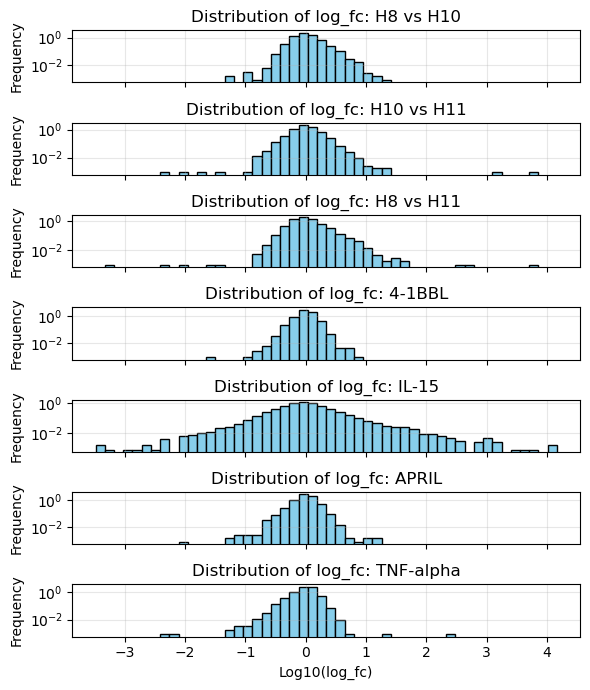

In [79]:
# Define the three comparisons we want to plot
target_comparisons = ["H8 vs H10", "H10 vs H11", "H8 vs H11", "4-1BBL", "IL-15", "APRIL", "TNF-alpha"]
colors = ['skyblue', 'lightgreen', 'salmon', 'orange', 'purple', 'red', 'brown']
alpha_values = [0.2, 0.2, 0.2, 0.2, 0.2, 0.2, 0.2]

# Determine common bin edges for all comparisons
all_log_fc_values = []
for comparison in target_comparisons:
    if comparison in data["comparison"].unique():
        subset_df = data[data["comparison"] == comparison]
        all_log_fc_values.extend(subset_df["log_fc"].tolist())

# Create common bins based on all data
min_val = min(all_log_fc_values)
max_val = max(all_log_fc_values)
common_bins = np.linspace(min_val, max_val, 51)  # 31 points make 30 bins

# Create a figure with subplots for each comparison
n_comparisons = len(target_comparisons)
fig, axes = plt.subplots(n_comparisons, 1, figsize=(6, n_comparisons * 1), sharex=True)

# Plot histogram for each comparison
for i, comparison in enumerate(target_comparisons):
    subset_df = data[data["comparison"] == comparison]
    axes[i].hist(subset_df["log_fc"], bins=common_bins, color='skyblue', edgecolor='black', density=True)
    axes[i].set_ylabel('Frequency')
    axes[i].set_yscale('log')
    axes[i].set_title(f'Distribution of log_fc: {comparison}')
    axes[i].grid(True, alpha=0.3)

# Set common x-label
plt.xlabel('Log10(log_fc)')
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "log_fc_dist"), dpi=300)

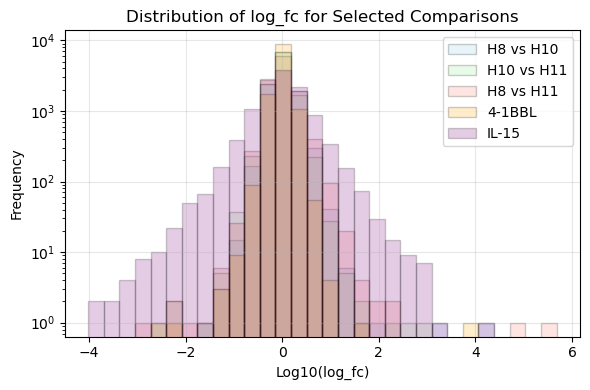

In [55]:
# Create a figure for the three specific comparisons
fig, ax = plt.subplots(figsize=(6, 4))

# Plot histogram for each of the three comparisons using the common bins
for i, comparison in enumerate(target_comparisons):
    if comparison in data["comparison"].unique():
        subset_df = data[data["comparison"] == comparison]
        ax.hist(subset_df["log_fc"], bins=common_bins, color=colors[i], 
                edgecolor='black', alpha=alpha_values[i], 
                label=comparison)

ax.set_ylabel('Frequency')
ax.set_yscale('log')
ax.set_title('Distribution of log_fc for Selected Comparisons')
ax.grid(True, alpha=0.3)
ax.legend()

# Set x-label
plt.xlabel('Log10(log_fc)')
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "selected_log_fc_dist"), dpi=300)

In [ ]:
# Create a figure for the three specific comparisons
fig, ax = plt.subplots(figsize=(6, 4))

# Define the three comparisons we want to plot
#target_comparisons = ["H8 vs H10", "H10 vs H11", "H8 vs H11", "4-1BBL", "IL-15"]
target_comparisons = ["H8 vs H10", "H10 vs H11", "H8 vs H11", "4-1BBL", "IL-15"]
colors = ['skyblue', 'lightgreen', 'salmon', 'orange', 'purple']
alpha_values = [0.2, 0.2, 0.2, 0.2, 0.2]

# Determine common bin edges for all comparisons
all_log_fc_values = []
for comparison in target_comparisons:
    if comparison in data["comparison"].unique():
        subset_df = data[data["comparison"] == comparison]
        all_log_fc_values.extend(subset_df["log_fc"].tolist())

# Create common bins based on all data
min_val = min(all_log_fc_values)
max_val = max(all_log_fc_values)
common_bins = np.linspace(min_val, max_val, 31)  # 31 points make 30 bins

# Plot histogram for each of the three comparisons using the common bins
for i, comparison in enumerate(target_comparisons):
    if comparison in data["comparison"].unique():
        subset_df = data[data["comparison"] == comparison]
        ax.hist(subset_df["log_fc"], bins=common_bins, color=colors[i], 
                edgecolor='black', alpha=alpha_values[i], 
                label=comparison)

ax.set_ylabel('Frequency')
ax.set_yscale('log')
ax.set_title('Distribution of log_fc for Selected Comparisons')
ax.grid(True, alpha=0.3)
ax.legend()

# Set x-label
plt.xlabel('Log10(log_fc)')
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "selected_log_fc_dist"), dpi=300)

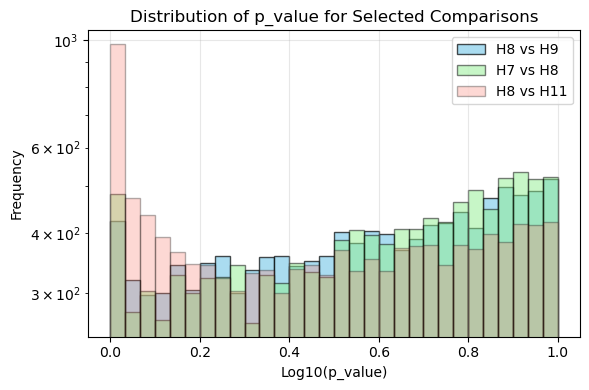

In [18]:
# Create a figure for the three specific comparisons
fig, ax = plt.subplots(figsize=(6, 4))

# Define the three comparisons we want to plot
target_comparisons = ["H8 vs H9", "H7 vs H8", "H8 vs H11"]
colors = ['skyblue', 'lightgreen', 'salmon']
alpha_values = [0.7, 0.5, 0.3]

# Determine common bin edges for all comparisons
all_p_values = []
for comparison in target_comparisons:
    if comparison in data["comparison"].unique():
        subset_df = data[data["comparison"] == comparison]
        all_p_values.extend(subset_df["p_value"].tolist())

# Create common bins based on all data
min_val = min(all_p_values)
max_val = max(all_p_values)
common_bins = np.linspace(min_val, max_val, 31)  # 31 points make 30 bins

# Plot histogram for each of the three comparisons using the common bins
for i, comparison in enumerate(target_comparisons):
    if comparison in data["comparison"].unique():
        subset_df = data[data["comparison"] == comparison]
        ax.hist(subset_df["p_value"], bins=common_bins, color=colors[i], 
                edgecolor='black', alpha=alpha_values[i], 
                label=comparison)

ax.set_ylabel('Frequency')
ax.set_yscale('log')
ax.set_title('Distribution of p_value for Selected Comparisons')
ax.grid(True, alpha=0.3)
ax.legend()

# Set x-label
plt.xlabel('Log10(p_value)')
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "selected_p_value_dist"), dpi=300)

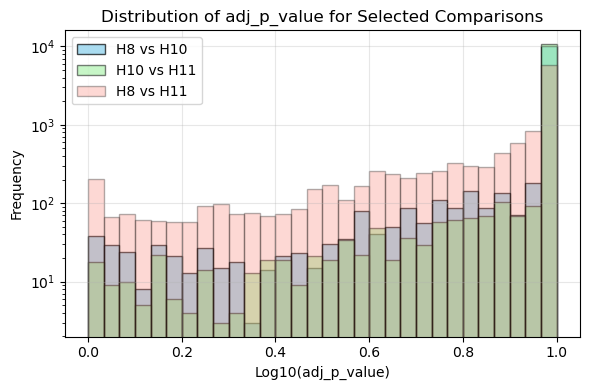

In [43]:
# Create a figure for the three specific comparisons
fig, ax = plt.subplots(figsize=(6, 4))

# Determine common bin edges for all comparisons
all_p_values = []
for comparison in target_comparisons:
    if comparison in data["comparison"].unique():
        subset_df = data[data["comparison"] == comparison]
        all_p_values.extend(subset_df["adj_p_value"].tolist())

# Create common bins based on all data
min_val = min(all_p_values)
max_val = max(all_p_values)
common_bins = np.linspace(min_val, max_val, 31)  # 31 points make 30 bins

# Plot histogram for each of the three comparisons using the common bins
for i, comparison in enumerate(target_comparisons):
    if comparison in data["comparison"].unique():
        subset_df = data[data["comparison"] == comparison]
        ax.hist(subset_df["adj_p_value"], bins=common_bins, color=colors[i], 
                edgecolor='black', alpha=alpha_values[i], 
                label=comparison)

ax.set_ylabel('Frequency')
ax.set_yscale('log')
ax.set_title('Distribution of adj_p_value for Selected Comparisons')
ax.grid(True, alpha=0.3)
ax.legend()

# Set x-label
plt.xlabel('Log10(adj_p_value)')
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "selected_adj_p_value_dist"), dpi=300)

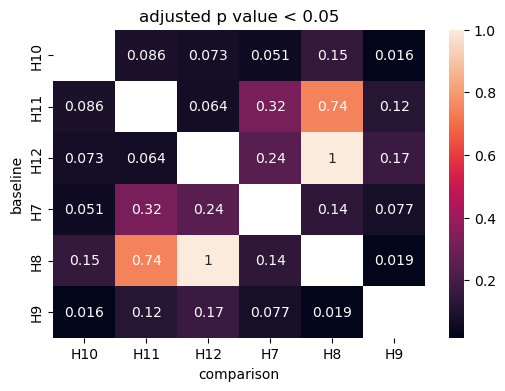

In [54]:
plt.figure(figsize=(6,4))
heatmap = data.groupby("comparison")["significant_0_05"].sum().to_frame()
heatmap["baseline"] = heatmap.index.str.split(" vs ").str[0]
heatmap["comparison"] = heatmap.index.str.split(" vs ").str[1]
heatmap = heatmap.pivot(index="baseline", columns="comparison", values="significant_0_05")
heatmap = heatmap / heatmap.max().max()
sns.heatmap(heatmap, annot=True)
plt.title("adjusted p value < 0.05")
plt.savefig(os.path.join(plot_folder, "heatmap_adjusted_p_value.png"), dpi=300)


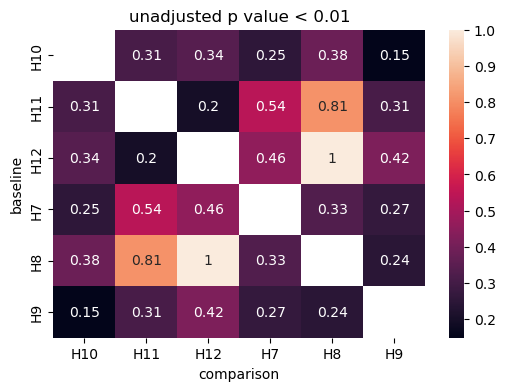

In [56]:
plt.figure(figsize=(6,4))
heatmap = data.groupby("comparison")["significant_0_01_uncorrected"].sum().to_frame()
heatmap["baseline"] = heatmap.index.str.split(" vs ").str[0]
heatmap["comparison"] = heatmap.index.str.split(" vs ").str[1]
heatmap = heatmap.pivot(index="baseline", columns="comparison", values="significant_0_01_uncorrected")
heatmap = heatmap / heatmap.max().max()
sns.heatmap(heatmap, annot=True)
plt.title("unadjusted p value < 0.01")
plt.savefig(os.path.join(plot_folder, "heatmap_unadjusted_p_value.png"), dpi=300)


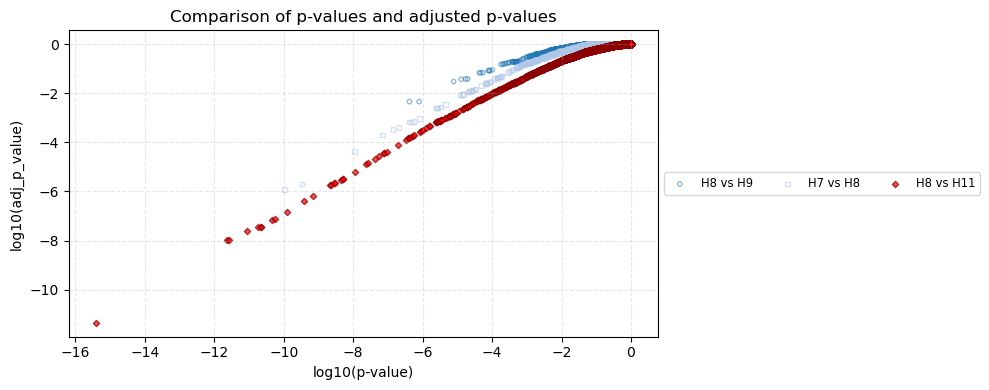

In [23]:
plt.figure(figsize=(10,4))

# Define marker styles and colors
markers = ['o', 's', 'D', '^', 'v', '<', '>', 'p', '*', 'h', 'H', '.', '|']  # Replaced '+' and 'x' with '.' and '|'
colors = plt.cm.tab20.colors  # Use a colormap with many distinct colors

# Create a function to determine if a comparison contains both H8 and (H11 or H12)
def is_special_case(comparison):
    return "H8" in comparison and ("H11" in comparison or "H12" in comparison)

# Plot each comparison that meets our criteria
for i, comparison in enumerate(target_comparisons):
    subset_df = data[data["comparison"] == comparison]
    
    # Special styling for H8 with H11 or H12
    if is_special_case(comparison):
        # Use red color family and filled markers for special cases
        marker_style = markers[i % len(markers)]
        plt.scatter(np.log10(subset_df["p_value"]), 
                   np.log10(subset_df['adj_p_value']), 
                   label=comparison, 
                   marker=marker_style,
                   color='red',  # Red for all special cases
                   edgecolor='darkred',
                   s=10,
                   alpha=0.7)
    else:
        # Use other colors and hollow markers for regular cases
        marker_style = markers[i % len(markers)]
        color_idx = i % len(colors)
        plt.scatter(np.log10(subset_df["p_value"]), 
                   np.log10(subset_df['adj_p_value']), 
                   label=comparison, 
                   marker=marker_style,
                   facecolor='none',
                   edgecolor=colors[color_idx],
                   s=10,
                   alpha=0.5)

plt.xlabel('log10(p-value)')
plt.ylabel('log10(adj_p_value)')
plt.title('Comparison of p-values and adjusted p-values')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend(ncol=3, loc="center left", bbox_to_anchor=(1, 0.5), fontsize='small')
plt.tight_layout()
plt.savefig(os.path.join(plot_folder, "p_value_comparison_scatter.png"), dpi= 300)
plt.show()

In [8]:
# Pivot the dataframe to make 'variable' the index, 'comparison' the columns, and 'p_value' the values
pivoted_data = data.pivot(index='variable', columns='comparison', values='p_value')
pivoted_data = np.log10(pivoted_data)

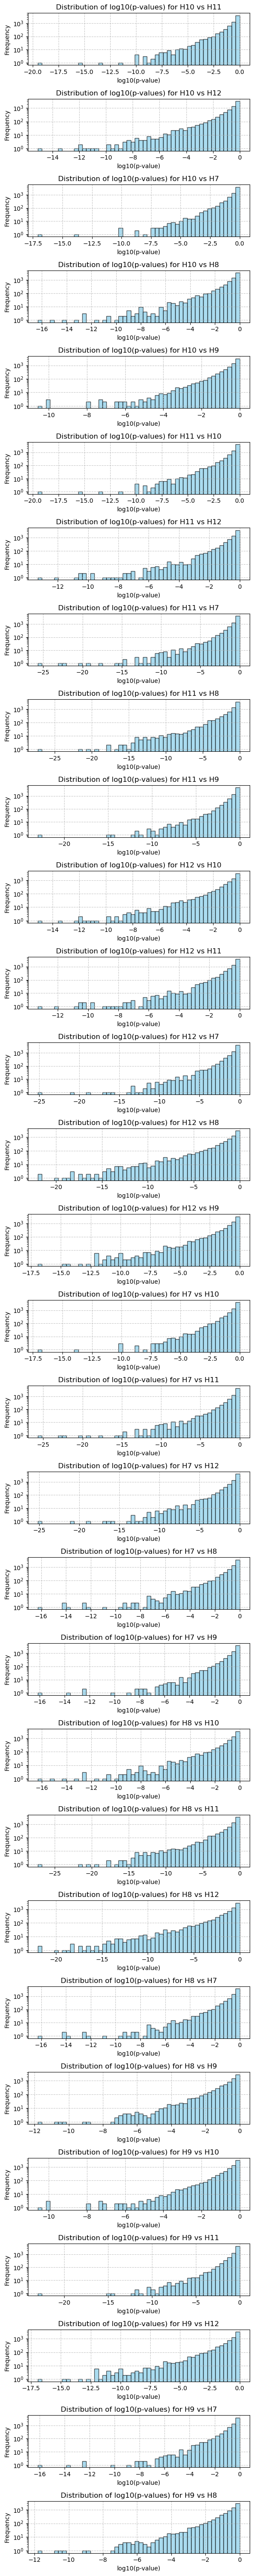

In [31]:
# Create a figure with subplots for each comparison
fig, axes = plt.subplots(nrows=len(pivoted_data.columns), figsize=(6, 2*len(pivoted_data.columns)))

# If there's only one comparison, axes will be a single axis rather than an array
if len(pivoted_data.columns) == 1:
    axes = [axes]

# Create a histogram for each comparison
for i, comparison in enumerate(pivoted_data.columns):
    # Get the data for this comparison, dropping NaN values
    column_data = pivoted_data[comparison].dropna()
    
    # Create the histogram
    axes[i].hist(column_data, bins=50, alpha=0.7, color='skyblue', edgecolor='black')
    
    # Add labels and title
    axes[i].set_xlabel('log10(p-value)')
    axes[i].set_ylabel('Frequency')
    axes[i].set_title(f'Distribution of log10(p-values) for {comparison}')
    
    axes[i].set_yscale('log')
    
    # Add grid for better readability
    axes[i].grid(True, linestyle='--', alpha=0.7)

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()
